# setup

In [21]:
import numpy as np
import pandas as pd
import qiime2 as q2
import seaborn as sns
import scipy.stats as st

import matplotlib.pyplot as plt
%matplotlib inline

data_dir="../../data"

In [2]:
ft = pd.read_csv(f"{data_dir}/feature-table.tsv", sep="\t", skiprows=1, index_col=0)

In [22]:
ft.head()

,SRR25052448,SRR25052449,SRR25052450,SRR25052451,SRR25052452,SRR25052453,SRR25052454,SRR25052455,SRR25052456,SRR25052458,...,SRR25052710,SRR25052711,SRR25052712,SRR25052713,SRR25052714,SRR25052715,SRR25052716,SRR25052717,SRR25052719,SRR25052720
#OTU ID,,,,,,,,,,,,,,,,,,,,,
100177,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100225,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,2.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0
1002546,0.0,2.0,1.0,2.0,6.0,0.0,2.0,1.0,0.0,4.0,...,7.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1002672,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1002689,0.0,2.0,0.0,0.0,0.0,0.0,7.0,0.0,0.0,15.0,...,9.0,0.0,0.0,0.0,0.0,0.0,0.0,18.0,2.0,0.0


# sparsity

Zero fraction: 76.5%
Taxa detected in <10% of samples: 32.3%


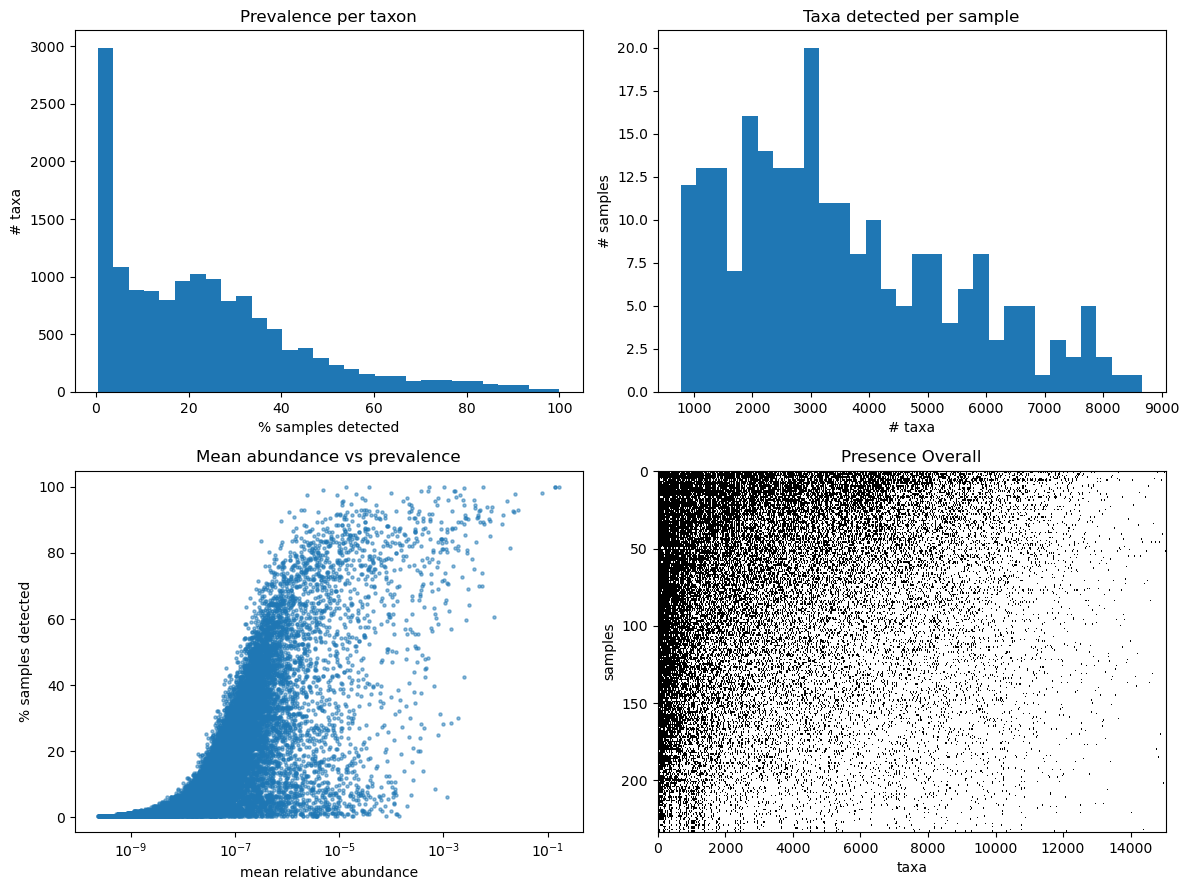

In [26]:
# ft: taxa x samples, raw counts
ft_s = ft.T                                   # samples x taxa
rel = ft_s.div(ft_s.sum(axis=1), axis=0)      # samples x taxa, relative abundance
present = ft_s > 0
prev = present.mean(axis=0)                   # per taxon
rich = present.sum(axis=1)                    # per sample

print(f"Zero fraction: {(~present).to_numpy().mean():.1%}")
print(f"Taxa detected in <10% of samples: {(prev < 0.1).mean():.1%}")

fig, ax = plt.subplots(2, 2, figsize=(12, 9))
ax[0, 0].hist(prev * 100, bins=30)
ax[0, 0].set(title="Prevalence per taxon", xlabel="% samples detected", ylabel="# taxa")

ax[0, 1].hist(rich, bins=30)
ax[0, 1].set(title="Taxa detected per sample", xlabel="# taxa", ylabel="# samples")

ax[1, 0].scatter(rel.mean(axis=0), prev * 100, s=5, alpha=.5)   # both indexed by taxon
ax[1, 0].set(xscale="log", title="Mean abundance vs prevalence",
             xlabel="mean relative abundance", ylabel="% samples detected")

order_t = prev.sort_values(ascending=False).index
order_s = rich.sort_values(ascending=False).index
ax[1, 1].imshow(present.loc[order_s, order_t].to_numpy(), aspect="auto",
                cmap="Greys", interpolation="nearest")
ax[1, 1].set(title="Presence Overall", xlabel="taxa", ylabel="samples")
plt.tight_layout()

# non-normality

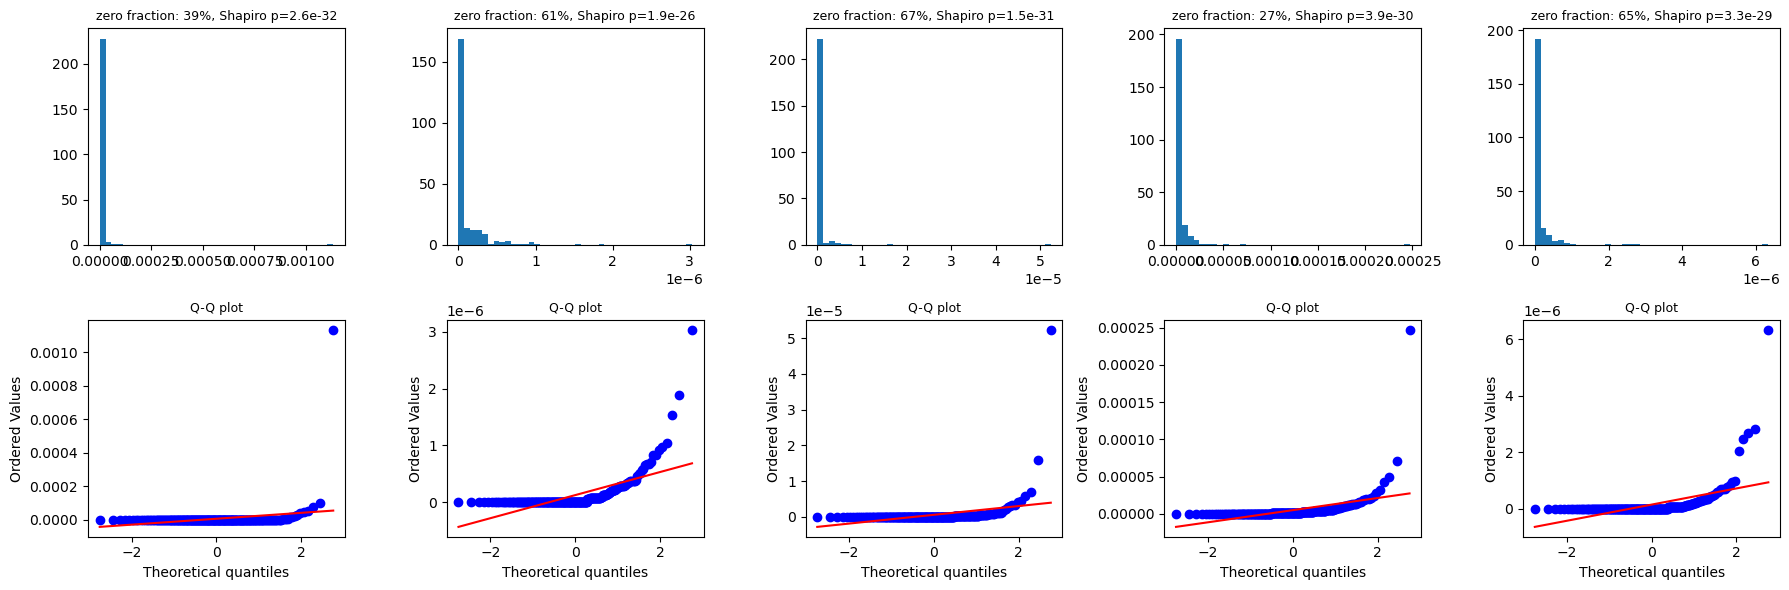

In [43]:
import scipy.stats as st

rng = np.random.default_rng(42)
cand = prev[prev >= 0.3].index                 # drop this line to sample from all taxa
taxa = rng.choice(cand, 5, replace=False)

fig, ax = plt.subplots(2, 5, figsize=(18, 6))
for j, t in enumerate(taxa):
    x = rel[t]                                 # rel: samples x taxa
    ax[0, j].hist(x, bins=40)
    ax[0, j].set_title(f"zero fraction: {(x==0).mean():.0%}, Shapiro p={st.shapiro(x)[1]:.1e}", fontsize=9)
    st.probplot(x, dist="norm", plot=ax[1, j])
    ax[1, j].set_title("Q-Q plot", fontsize=9)
plt.tight_layout()